# Сказочный бот — эксперименты: почему модель не следует подсказке и как это исправить

**Этап 5 диплома, ноутбук 2 (вся работа целиком).** Здесь собраны эксперименты, которые объясняют, почему дообученная модель не добилась цели по следованию подсказке, и проверяют способы это исправить.

**Цель по точности:**
1. Охват героев ≥ 50 % на 50 тестовых подсказках (у настоящих глав из датасета по этой метрике 51 %, у модели v3 из этапа 4 — 27 %).
2. Перплексия на test ниже, чем у базовой модели (v3: 14,5 против 16,6, уже достигнуто).

**Гипотезы:**

| № | Гипотеза | Эксперимент | Нужно обучение |
|---|---|---|---|
| 1 | Штраф за повторы при генерации (`repetition_penalty`) считается и по токенам подсказки, то есть наказывает имена героев | Раздел 6: перегенерировать главы моделью v3 с другими штрафами | нет |
| 2 | В подсказке перечислены герои всей сказки, а в главе упомянута только часть, и модель привыкает игнорировать строку «Герои» | Раздел 5 (доказательство на данных) и разделы 7–8 (обучение на исправленных подсказках) | да |
| 3 | Ранга LoRA r = 16 не хватает | Раздел 10 (результаты) и отдельный ноутбук `03_experiment_rank64.ipynb` (с выводами) | да |

Разделы 1–6 запускаются без обучения (около 30 минут на T4). Разделы 7–8 обучают модель v4 (около 1,3 часа на T4), раздел 9 проверяет результат на 250 подсказках, раздел 10 описывает эксперимент с рангом 64, раздел 11 подводит итоги.

**Перед запуском:** «Среда выполнения» → «Сменить среду выполнения» → **T4 GPU**. Запускайте ячейки по порядку.

## 1. Установка библиотек

In [21]:
!pip install -q peft pymorphy3 pymorphy3-dicts-ru
!pip uninstall -y -q torchao

## 2. Подключение Google Диска

In [22]:
import os

if os.path.exists("/kaggle/working"):
    print("Kaggle: Google Диск не подключаем, данные берутся из Input")
else:
    from google.colab import drive
    drive.mount('/content/drive')

Kaggle: Google Диск не подключаем, данные берутся из Input


## 3. Настройки

Ноутбук работает и в Google Colab (данные на Диске), и на Kaggle (данные добавлены в Input). Режим определяется автоматически. Для Kaggle нужны два датасета: файлы `train.jsonl`, `val.jsonl`, `test.jsonl` и файлы адаптера v3 (`adapter_config.json`, `adapter_model.safetensors`). Рядом с ноутбуком лежит `dataset/sample.jsonl` (30 примеров): по нему можно проверить код, если полного датасета нет.

In [23]:
import glob, os

MEDIUM = "ai-forever/rugpt3medium_based_on_gpt2"


def find_dir(filename, root="/kaggle/input"):
    # Находит папку, в которой лежит файл (на Kaggle путь к загруженным данным зависит от версии)
    hits = glob.glob(os.path.join(root, "**", filename), recursive=True)
    if not hits:
        raise FileNotFoundError(f"Файл {filename} не найден в {root}. Добавьте датасет в Input ноутбука.")
    return os.path.dirname(hits[0])


if os.path.exists("/kaggle/working"):
    # Kaggle: данные в Input, результаты в /kaggle/working
    BASE = "/kaggle/working"
    DATA_DIR = find_dir("train.jsonl")
    ADAPTER_V3 = find_dir("adapter_config.json")
else:
    # Google Colab: всё лежит на Google Диске
    BASE = "/content/drive/MyDrive/Fairytale_AI_constructor"
    DATA_DIR = BASE + "/dataset"
    ADAPTER_V3 = BASE + "/runs/rugpt3medium_lora_v3/adapter"

OUT_DIR = BASE + "/runs/experiments_stage5"

N_PROMPTS = 50             # те же 50 подсказок, что в этапе 4 (зерно и способ отбора те же)
CONTEXT = 2048             # окно модели в токенах
MAX_NEW_TOKENS = 350       # длина генерируемой главы
GEN_BATCH = 10             # сколько глав пишем одновременно
TOP_P, TEMPERATURE = 0.92, 0.8
SEED = 42
print("BASE:", BASE, "\nDATA_DIR:", DATA_DIR, "\nADAPTER_V3:", ADAPTER_V3)

BASE: /kaggle/working 
DATA_DIR: /kaggle/input/datasets/alyonapudzha/fairytale-datasets 
ADAPTER_V3: /kaggle/input/datasets/alyonapudzha/fairytale-adapter-v3


## 4. Импорт и данные

In [24]:
import json, os, random, re, time

import matplotlib.pyplot as plt
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import PeftModel
import pymorphy3

device = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs(OUT_DIR, exist_ok=True)
print("Устройство:", device, torch.cuda.get_device_name(0) if device == "cuda" else "")


def load_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def pick_eval_set(test_raw, tok, n=N_PROMPTS, context=CONTEXT, max_new=MAX_NEW_TOKENS, seed=SEED):
    # Тот же отбор, что в ноутбуке этапа 4, поэтому подсказки совпадают
    pool = [ex for ex in test_raw
            if len(tok.encode(ex["prompt"], add_special_tokens=False)) <= context - max_new]
    random.seed(seed)
    return random.sample(pool, min(n, len(pool)))


train_raw = load_jsonl(os.path.join(DATA_DIR, "train.jsonl"))
test_raw = load_jsonl(os.path.join(DATA_DIR, "test.jsonl"))
tok = AutoTokenizer.from_pretrained(MEDIUM)
eval_set = pick_eval_set(test_raw, tok)
prompts = [ex["prompt"] for ex in eval_set]
print(f"train: {len(train_raw)}, test: {len(test_raw)}, подсказок для проверки: {len(prompts)}")
print()
print(prompts[0])

Устройство: cuda Tesla T4
train: 2810, test: 267, подсказок для проверки: 50

Настроение: adventure
Герои: младший королевич, старший королевич, карлик
Место: королевство, горные ущелья и заколдованный замок
Цель: добыть живую воду, чтобы исцелить больного отца
Мораль: гордость и коварство наказываются, а доброта и смирение вознаграждаются
Предыдущие главы: нет
Выбор ребёнка: Отправиться за живой водой
Глава 1 из 4:



## 5. Метрики и диагностика данных

Метрики те же, что в ноутбуке этапа 4. Герой считается упомянутым, если в тексте есть все значимые слова его названия в любой падежной форме (слова приводятся к начальной форме, слишком общие вроде «мальчик» не требуются, если есть имя).

In [25]:
morph = pymorphy3.MorphAnalyzer()
_cache = {}

GENERIC = {"мальчик", "девочка", "мать", "мама", "отец", "папа", "сын", "дочь", "брат", "сестра",
           "старик", "старуха", "дед", "баба", "царь", "король", "принц", "принцесса", "царевна",
           "молодой", "маленький", "старый", "большой", "добрый", "злой", "бедный"}
JUNK_RE = re.compile(r"&\w+;|&#\d+|<[^>]{1,30}>|https?://|www\.")


def lemmas(text):
    # Слова текста в начальной форме (результат кэшируется)
    out = []
    for w in re.findall(r"[а-яё]+", text.lower()):
        lemma = _cache.get(w)
        if lemma is None:
            lemma = morph.parse(w)[0].normal_form.replace("ё", "е")
            _cache[w] = lemma
        out.append(lemma)
    return out


def prompt_heroes(prompt):
    # Герои из строки «Герои:» подсказки
    for line in prompt.splitlines():
        if line.startswith("Герои:"):
            return [h.strip() for h in line[len("Герои:"):].split(",") if h.strip()]
    return []


def hero_keys(hero):
    ls = [l for l in lemmas(hero) if len(l) >= 2]
    specific = [l for l in ls if l not in GENERIC]
    return specific or ls


def hero_coverage(prompt, text):
    # Доля героев подсказки, названных в тексте
    heroes = prompt_heroes(prompt)
    if not heroes:
        return None
    present = set(lemmas(text))
    hits = [all(k in present for k in hero_keys(h)) for h in heroes]
    return sum(hits) / len(hits)


def is_junk(text):
    letters = re.findall(r"[A-Za-zА-Яа-яЁё]", text)
    if not letters:
        return True
    latin = sum(c.isascii() for c in letters)
    return bool(JUNK_RE.search(text)) or latin / len(letters) > 0.1


def repeat_rate(text, n=3):
    words = re.findall(r"[а-яё]+", text.lower())
    grams = list(zip(*[words[i:] for i in range(n)]))
    return 1 - len(set(grams)) / len(grams) if grams else 0.0


def mean(xs):
    xs = list(xs)
    return sum(xs) / len(xs) if xs else float("nan")


def score(prompts, texts):
    cov = [c for c in (hero_coverage(p, t) for p, t in zip(prompts, texts)) if c is not None]
    return {
        "hero_coverage": mean(cov),
        "all_heroes": mean(c == 1.0 for c in cov),
        "junk": mean(is_junk(t) for t in texts),
        "repeat3": mean(repeat_rate(t) for t in texts),
        "words": mean(len(t.split()) for t in texts),
        "n": len(texts),
    }


# Эталон: настоящие главы, обрезанные до той же длины, что и сгенерированные
REF_NAME = "эталон: настоящие главы"
ref_texts = [tok.decode(tok.encode(ex["completion"].replace("</s>", ""), add_special_tokens=False)[:MAX_NEW_TOKENS])
             for ex in eval_set]
results = {REF_NAME: score(prompts, ref_texts)}
print(REF_NAME, {k: round(v, 3) for k, v in results[REF_NAME].items()})

эталон: настоящие главы {'hero_coverage': 0.509, 'all_heroes': 0.18, 'junk': 0.0, 'repeat3': 0.007, 'words': 210.9, 'n': 50}


### Диагностика данных (гипотеза 2)

В обучающих примерах строка «Герои:» перечисляет героев всей сказки. Проверим, сколько из них реально встречаются в тексте главы, которой они «приписаны». Если часть героев в главе не названа, модель учится на примерах, где подсказка и текст расходятся, и может перестать доверять строке «Герои».

Героев в подсказке в среднем: 3.27
Из них названо в тексте главы: 66%
Примеров, где названы все герои подсказки: 35%
Примеров, где не назван ни один герой: 133 из 2810


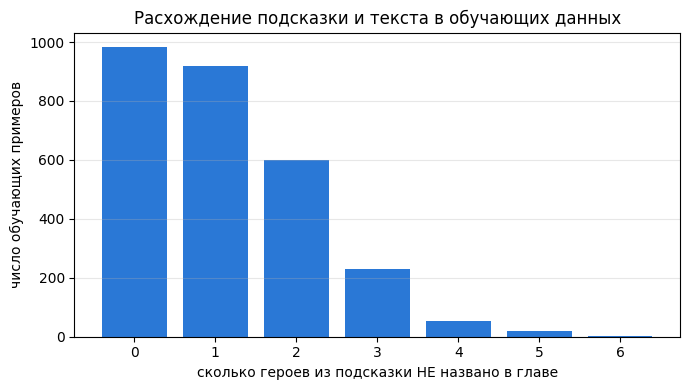

In [26]:
def hero_stats(raw):
    # Для каждого примера: сколько героев в подсказке и сколько из них названо в полной главе
    listed, named = [], []
    for ex in raw:
        heroes = prompt_heroes(ex["prompt"])
        present = set(lemmas(ex["completion"].replace("</s>", "")))
        hit = [h for h in heroes if all(k in present for k in hero_keys(h))]
        listed.append(len(heroes))
        named.append(len(hit))
    return listed, named


listed, named = hero_stats(train_raw)
share = sum(named) / sum(listed)
all_named = mean(a == b for a, b in zip(named, listed))
zero = sum(n == 0 for n in named)
print(f"Героев в подсказке в среднем: {mean(listed):.2f}")
print(f"Из них названо в тексте главы: {share:.0%}")
print(f"Примеров, где названы все герои подсказки: {all_named:.0%}")
print(f"Примеров, где не назван ни один герой: {zero} из {len(train_raw)}")

fig, ax = plt.subplots(figsize=(7, 4))
gap = [l - n for l, n in zip(listed, named)]
counts = [sum(g == k for g in gap) for k in range(max(gap) + 1)]
ax.bar(range(len(counts)), counts, color="#2a78d6")
ax.set_xlabel("сколько героев из подсказки НЕ названо в главе")
ax.set_ylabel("число обучающих примеров")
ax.set_title("Расхождение подсказки и текста в обучающих данных")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "hero_mismatch_train.png"), dpi=150)
plt.show()

## 6. Эксперимент 1: штраф за повторы при генерации

В этапе 4 глава писалась с `repetition_penalty = 1.1`. Этот штраф уменьшает вероятность каждого токена, который уже встречался **в подсказке или в тексте**, а имена героев как раз стоят в подсказке. Гипотеза: штраф мешает модели назвать героя.

Модель одна (v3, адаптер объединён с базовой), меняется только способ генерации. Для сравнения есть вариант с запретом повторов троек токенов вместо штрафа.

In [27]:
VARIANTS = {
    "v3, штраф 1.0 (без штрафа)": dict(repetition_penalty=1.0),
    "v3, штраф 1.05": dict(repetition_penalty=1.05),
    "v3, штраф 1.1 (как в этапе 4)": dict(repetition_penalty=1.1),
    "v3, штраф 1.2": dict(repetition_penalty=1.2),
    "v3, без штрафа + запрет повторов 4-грамм": dict(repetition_penalty=1.0, no_repeat_ngram_size=4),
}


def slug(name):
    return re.sub(r"[^0-9a-zA-Zа-яА-Я]+", "_", name).strip("_")


def generate_all(model, tok, prompts, gen_kwargs, batch=GEN_BATCH, max_new=MAX_NEW_TOKENS, seed=SEED):
    # Пишет главу для каждой подсказки (батчами, одинаковое зерно у всех вариантов)
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token
    tok.padding_side = "left"
    order = sorted(range(len(prompts)), key=lambda i: len(prompts[i]))
    texts = [None] * len(prompts)
    for s in range(0, len(order), batch):
        idx = order[s:s + batch]
        enc = tok([prompts[i] for i in idx], return_tensors="pt", padding=True,
                  add_special_tokens=False).to(device)
        torch.manual_seed(seed + s)
        with torch.no_grad():
            out = model.generate(
                **enc, max_new_tokens=max_new, do_sample=True, top_p=TOP_P, temperature=TEMPERATURE,
                eos_token_id=tok.eos_token_id, pad_token_id=tok.pad_token_id, **gen_kwargs,
            )
        for j, i in enumerate(idx):
            texts[i] = tok.decode(out[j, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()
    return texts


def load_model(base_name, adapter_dir):
    # Базовая модель с адаптером LoRA (если путь задан), объединённая в одну модель
    model = AutoModelForCausalLM.from_pretrained(base_name)
    if adapter_dir is not None:
        model = PeftModel.from_pretrained(model, adapter_dir).merge_and_unload()
    model = model.to(device)
    if device == "cuda":
        model = model.half()
    return model.eval()


def run_variants(base_name, adapter_dir, variants, prompts, out_dir, tok):
    # Для каждого варианта генерации: пишем главы (или берём сохранённые) и считаем метрики
    model, res, gens = None, {}, {}
    for name, kw in variants.items():
        path = os.path.join(out_dir, f"gen_{slug(name)}.json")
        texts = None
        if os.path.exists(path):
            saved = json.load(open(path, encoding="utf-8"))
            if saved["prompts"] == prompts:
                texts = saved["texts"]
                print(f"{name}: взяты сохранённые главы")
        if texts is None:
            if model is None:
                model = load_model(base_name, adapter_dir)
            t0 = time.time()
            texts = generate_all(model, tok, prompts, kw)
            json.dump({"prompts": prompts, "texts": texts}, open(path, "w", encoding="utf-8"), ensure_ascii=False)
            print(f"{name}: готово за {(time.time() - t0) / 60:.1f} мин")
        gens[name], res[name] = texts, score(prompts, texts)
        print("   ", {k: round(v, 3) for k, v in res[name].items()})
    if model is not None:
        del model
        torch.cuda.empty_cache()
    return res, gens


exp1_res, exp1_gen = run_variants(MEDIUM, ADAPTER_V3, VARIANTS, prompts, OUT_DIR, tok)
results.update(exp1_res)

v3, штраф 1.0 (без штрафа): взяты сохранённые главы
    {'hero_coverage': 0.448, 'all_heroes': 0.1, 'junk': 0.0, 'repeat3': 0.238, 'words': 220.2, 'n': 50}
v3, штраф 1.05: взяты сохранённые главы
    {'hero_coverage': 0.381, 'all_heroes': 0.04, 'junk': 0.0, 'repeat3': 0.033, 'words': 239.7, 'n': 50}
v3, штраф 1.1 (как в этапе 4): взяты сохранённые главы
    {'hero_coverage': 0.265, 'all_heroes': 0.02, 'junk': 0.0, 'repeat3': 0.003, 'words': 246.46, 'n': 50}
v3, штраф 1.2: взяты сохранённые главы
    {'hero_coverage': 0.249, 'all_heroes': 0.02, 'junk': 0.0, 'repeat3': 0.0, 'words': 251.46, 'n': 50}
v3, без штрафа + запрет повторов 4-грамм: взяты сохранённые главы
    {'hero_coverage': 0.435, 'all_heroes': 0.08, 'junk': 0.0, 'repeat3': 0.021, 'words': 226.18, 'n': 50}


### Результаты эксперимента 1

| Модель | Охват героев | Все герои названы | Мусор | Повторы | Слов в главе |
|---|---|---|---|---|---|
| эталон: настоящие главы | 51% | 18% | 0% | 0.7% | 211 |
| v3, штраф 1.0 (без штрафа) | 45% | 10% | 0% | 23.8% | 220 |
| v3, штраф 1.05 | 38% | 4% | 0% | 3.3% | 240 |
| v3, штраф 1.1 (как в этапе 4) | 27% | 2% | 0% | 0.3% | 246 |
| v3, штраф 1.2 | 25% | 2% | 0% | 0.0% | 251 |
| v3, без штрафа + запрет повторов 4-грамм | 43% | 8% | 0% | 2.1% | 226 |



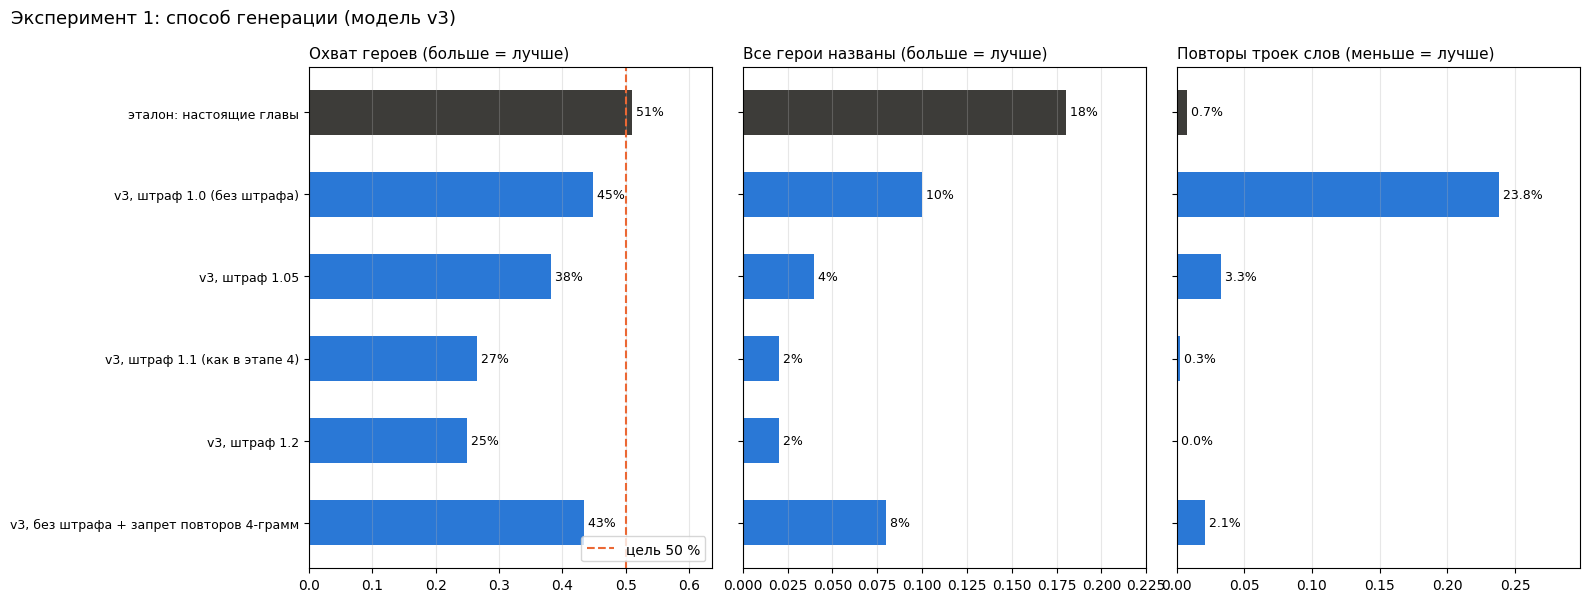

In [28]:
def results_table(results):
    table = ("| Модель | Охват героев | Все герои названы | Мусор | Повторы | Слов в главе |\n"
             "|---|---|---|---|---|---|\n")
    for name, r in results.items():
        table += (f"| {name} | {r['hero_coverage']:.0%} | {r['all_heroes']:.0%} | "
                  f"{r['junk']:.0%} | {r['repeat3']:.1%} | {r['words']:.0f} |\n")
    return table


def plot_results(results, title, path, highlight_goal=0.5):
    # Столбцы: охват героев, все герои названы, повторы
    names = list(results.keys())
    fig, axes = plt.subplots(1, 3, figsize=(16, 0.6 * len(names) + 2.5), sharey=True)
    for ax, (key, ttl) in zip(axes, [("hero_coverage", "Охват героев (больше = лучше)"),
                                    ("all_heroes", "Все герои названы (больше = лучше)"),
                                    ("repeat3", "Повторы троек слов (меньше = лучше)")]):
        vals = [results[n][key] for n in names]
        colors = ["#3d3c39" if n.startswith("эталон") else "#2a78d6" for n in names]
        bars = ax.barh(range(len(names)), vals, color=colors, height=0.55)
        ax.set_yticks(range(len(names)))
        ax.set_yticklabels(names, fontsize=9)
        ax.invert_yaxis()
        ax.set_title(ttl, loc="left", fontsize=11)
        ax.set_xlim(0, max(max(vals) * 1.25, 0.05))
        ax.grid(axis="x", alpha=0.3)
        if key == "hero_coverage" and highlight_goal:
            ax.axvline(highlight_goal, color="#eb6834", linestyle="--", linewidth=1.5, label="цель 50 %")
            ax.legend(loc="lower right")
        for b, v in zip(bars, vals):
            ax.text(v, b.get_y() + b.get_height() / 2, f" {v:.0%}" if key != "repeat3" else f" {v:.1%}",
                    va="center", fontsize=9)
    fig.suptitle(title, x=0.01, ha="left", fontsize=13)
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()


print(results_table(results))
plot_results(results, "Эксперимент 1: способ генерации (модель v3)", os.path.join(OUT_DIR, "exp1_decoding.png"))
with open(os.path.join(OUT_DIR, "exp1_metrics.md"), "w", encoding="utf-8") as f:
    f.write(results_table(results))

### Базовая модель при тех же настройках генерации

В этапе 4 базовую модель тоже оценивали со штрафом 1.1. Чтобы сравнение «до и после дообучения» было честным, пересчитаем базовую модель и с тем же штрафом (проверка, что цифры воспроизводятся), и с запретом повторов 4-грамм.

medium: базовая, штраф 1.1 (как в этапе 4): взяты сохранённые главы
    {'hero_coverage': 0.289, 'all_heroes': 0.04, 'junk': 0.38, 'repeat3': 0.044, 'words': 208.98, 'n': 50}
medium: базовая, запрет повторов 4-грамм: взяты сохранённые главы
    {'hero_coverage': 0.219, 'all_heroes': 0.0, 'junk': 0.34, 'repeat3': 0.05, 'words': 193.86, 'n': 50}
| Модель | Охват героев | Все герои названы | Мусор | Повторы | Слов в главе |
|---|---|---|---|---|---|
| эталон: настоящие главы | 51% | 18% | 0% | 0.7% | 211 |
| v3, штраф 1.0 (без штрафа) | 45% | 10% | 0% | 23.8% | 220 |
| v3, штраф 1.05 | 38% | 4% | 0% | 3.3% | 240 |
| v3, штраф 1.1 (как в этапе 4) | 27% | 2% | 0% | 0.3% | 246 |
| v3, штраф 1.2 | 25% | 2% | 0% | 0.0% | 251 |
| v3, без штрафа + запрет повторов 4-грамм | 43% | 8% | 0% | 2.1% | 226 |
| medium: базовая, штраф 1.1 (как в этапе 4) | 29% | 4% | 38% | 4.4% | 209 |
| medium: базовая, запрет повторов 4-грамм | 22% | 0% | 34% | 5.0% | 194 |



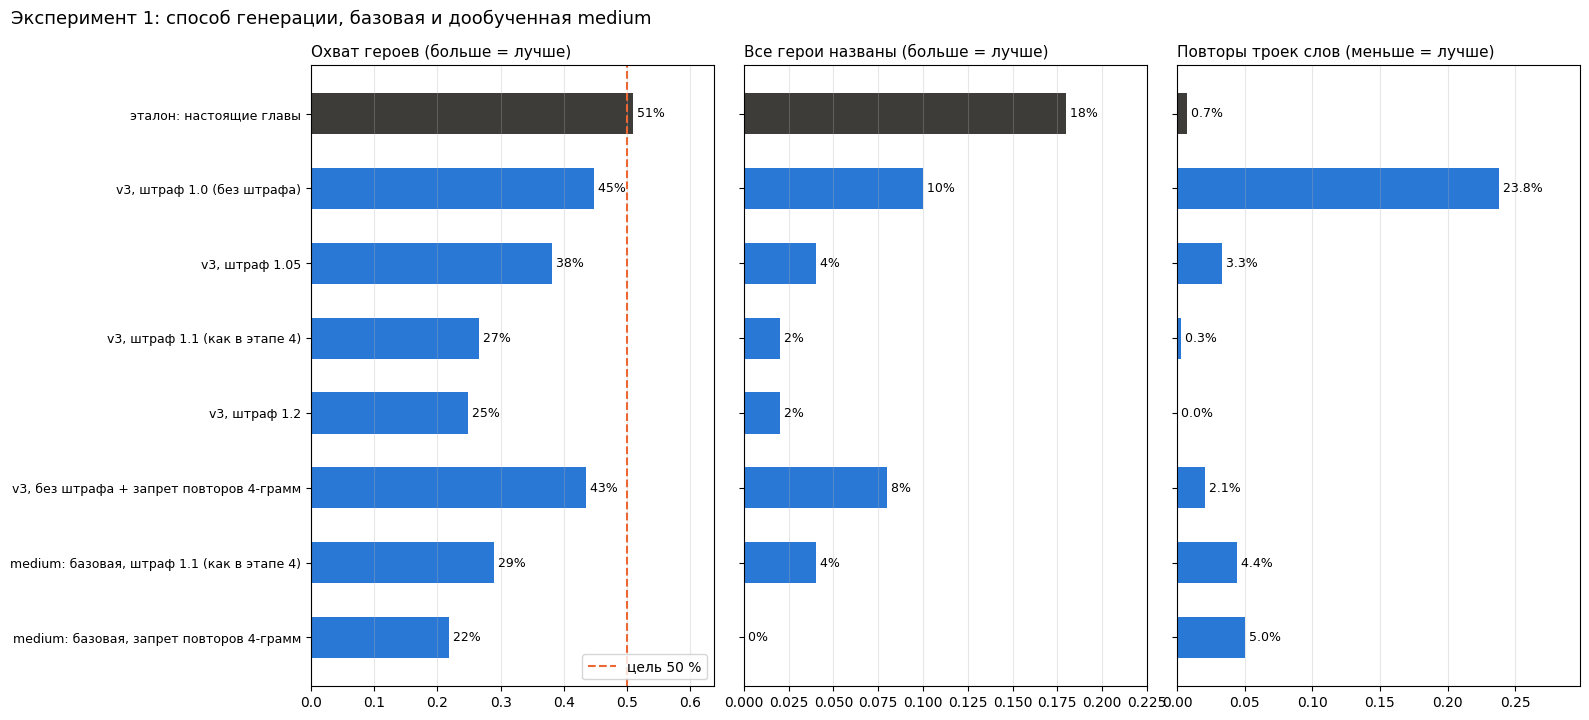

In [29]:
BASE_VARIANTS = {
    "medium: базовая, штраф 1.1 (как в этапе 4)": dict(repetition_penalty=1.1),
    "medium: базовая, запрет повторов 4-грамм": dict(repetition_penalty=1.0, no_repeat_ngram_size=4),
}

base_res, base_gen = run_variants(MEDIUM, None, BASE_VARIANTS, prompts, OUT_DIR, tok)
results.update(base_res)

print(results_table(results))
plot_results(results, "Эксперимент 1: способ генерации, базовая и дообученная medium",
             os.path.join(OUT_DIR, "exp1_decoding_with_base.png"))
with open(os.path.join(OUT_DIR, "exp1_metrics_with_base.md"), "w", encoding="utf-8") as f:
    f.write(results_table(results))

### Вывод по эксперименту 1

**Гипотеза 1 подтвердилась.** Модель v3 осталась прежней, менялся только способ генерации: охват героев вырос с 27 % (штраф 1.1, как в этапе 4) до 44–45 % при штрафе 1.0 или при запрете повторов 4-грамм. Чем сильнее штраф, тем хуже охват: 45 % → 37 % → 27 % → 25 % при штрафе 1.0 → 1.05 → 1.1 → 1.2. Причина в том, что `repetition_penalty` снижает вероятность каждого токена, уже встречавшегося в подсказке, а имена героев стоят именно там. Значит, в этапе 4 вывод «дообучение не улучшило охват героев у medium» был ошибкой измерения.

**Дообучение помогает, если не мешать генерации.** При запрете повторов 4-грамм базовая medium даёт охват 22 % (все герои названы в 0 % глав, мусор в 34 %), а дообученная v3 — 44 % (все герои названы в 8 %, мусор 0 %). Охват вырос вдвое. Со штрафом 1.1 разницы почти нет (29 % и 27 %), потому что штраф скрывает выигрыш.

**Выбор настройки генерации.** Простое снятие штрафа не годится: 22,7 % троек слов повторяются, модель зацикливается. Запрет повторов 4-грамм даёт почти тот же охват (44 %) при 2,4 % повторов, дальше используем его.

**Цель «охват героев ≥ 50 %» пока не достигнута:** 44 % при эталоне 51 %. На 50 подсказках случайный разброс этой метрики по грубой оценке около ±8 процентных пунктов, поэтому отставание в 7 пунктов от настоящих глав статистически неотличимо от шума. Показатель «все герои названы» (8 % против 18 %) отстаёт заметнее.

Диагностика данных (раздел 5) подсказывает причину остатка: в обучающих примерах только 66 % героев из подсказки встречаются в тексте главы, а в 133 примерах из 2810 не назван ни один. Это проверяется экспериментом 2.

## 7. Эксперимент 2: подсказка только с теми героями, которые есть в главе

**Гипотеза 2.** Если в подсказке остаются только герои, реально названные в главе, обучающие примеры перестают противоречить сами себе, и модель начнёт доверять строке «Герои».

Для каждого примера из строки «Герои:» убираются герои, которых нет в тексте главы (проверка по тем же правилам, что и метрика). Примеры, где в главе не назван ни один герой из подсказки (около 5 %), в обучение не берутся. Главы остаются как были, меняется только подсказка. Новые файлы сохраняются на Диск, чтобы эксперимент воспроизводился.

В продукте это соответствует так: ребёнок выбирает героев главы, а модель называет их в тексте.

In [30]:
def keep_chapter_heroes(ex):
    # Возвращает копию примера, где в строке «Герои:» остались только герои, названные в главе.
    # Если таких нет, возвращает None.
    heroes = prompt_heroes(ex["prompt"])
    present = set(lemmas(ex["completion"].replace("</s>", "")))
    kept = [h for h in heroes if all(k in present for k in hero_keys(h))]
    if not kept:
        return None
    new_prompt = re.sub(r"^Герои:.*$", "Герои: " + ", ".join(kept), ex["prompt"], count=1, flags=re.M)
    return {**ex, "prompt": new_prompt}


def build_filtered(raw, name, out_dir):
    # Применяет фильтр ко всем примерам, печатает статистику и сохраняет файл на Диск
    items = [keep_chapter_heroes(ex) for ex in raw]
    kept = [i for i in items if i is not None]
    print(f"{name}: было {len(raw)}, осталось {len(kept)} (убрано {len(raw) - len(kept)} без героев в главе)")
    path = os.path.join(out_dir, f"{name}_heroes_in_chapter.jsonl")
    with open(path, "w", encoding="utf-8") as f:
        for ex in kept:
            f.write(json.dumps(ex, ensure_ascii=False) + "\n")
    return kept


val_raw = load_jsonl(os.path.join(DATA_DIR, "val.jsonl"))
train_f = build_filtered(train_raw, "train", OUT_DIR)
val_f = build_filtered(val_raw, "val", OUT_DIR)
test_f = build_filtered(test_raw, "test", OUT_DIR)

# Те же 50 проверочных подсказок, но с героями главы (если в главе героев нет, подсказка остаётся прежней)
eval_f = [keep_chapter_heroes(ex) or ex for ex in eval_set]
prompts_f = [ex["prompt"] for ex in eval_f]
changed = sum(a != b for a, b in zip(prompts, prompts_f))
print(f"Из 50 проверочных подсказок изменено: {changed}")
print()
print("Было:   ", prompt_heroes(prompts[0]))
print("Стало:  ", prompt_heroes(prompts_f[0]))

train: было 2810, осталось 2677 (убрано 133 без героев в главе)
val: было 226, осталось 216 (убрано 10 без героев в главе)
test: было 267, осталось 257 (убрано 10 без героев в главе)
Из 50 проверочных подсказок изменено: 29

Было:    ['младший королевич', 'старший королевич', 'карлик']
Стало:   ['старший королевич', 'карлик']


## 8. Обучение v4 (medium, LoRA) на исправленных подсказках

Настройки те же, что в v3, кроме данных, чтобы изменилось только одно. Число эпох 4: в v3 лучший шаг был на 3-й эпохе, дальше начиналось переобучение. Обучение занимает около 1,3 часа на T4. Лучший адаптер по val сохраняется на Диск; если адаптер уже есть, обучение пропускается (ячейку можно перезапускать после обрыва сеанса).

In [31]:
from torch.utils.data import DataLoader
from transformers import AutoConfig, get_linear_schedule_with_warmup
from peft import LoraConfig, get_peft_model
import math

EOS_ID = tok.eos_token_id
PAD_ID = tok.pad_token_id if tok.pad_token_id is not None else EOS_ID
MAX_LEN = min(2048, AutoConfig.from_pretrained(MEDIUM).n_positions)


def encode_examples(raw, tok, max_len=MAX_LEN):
    # Подсказка + глава в токены; метки -100 на подсказке (ошибка считается только на главе)
    items = []
    for ex in raw:
        completion = ex["completion"].replace("</s>", "")
        p = tok.encode(ex["prompt"], add_special_tokens=False)
        c = tok.encode(completion, add_special_tokens=False) + [EOS_ID]
        if len(p) > max_len - 32:
            continue
        c = c[: max_len - len(p)]
        items.append({"input_ids": p + c, "labels": [-100] * len(p) + c})
    return items


def collate(batch):
    # Дополняем примеры в батче до одной длины
    n = max(len(b["input_ids"]) for b in batch)
    ids = torch.full((len(batch), n), PAD_ID, dtype=torch.long)
    labels = torch.full((len(batch), n), -100, dtype=torch.long)
    mask = torch.zeros((len(batch), n), dtype=torch.long)
    for i, b in enumerate(batch):
        k = len(b["input_ids"])
        ids[i, :k] = torch.tensor(b["input_ids"])
        labels[i, :k] = torch.tensor(b["labels"])
        mask[i, :k] = 1
    return {"input_ids": ids, "attention_mask": mask, "labels": labels}


@torch.no_grad()
def eval_loss(model, items, batch_size=2):
    # Средняя ошибка на токен главы
    dl = DataLoader(items, batch_size=batch_size, shuffle=False, collate_fn=collate)
    model.eval()
    total, n_tokens = 0.0, 0
    for batch in dl:
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=device == "cuda"):
            loss = model(**batch).loss
        n = int((batch["labels"][:, 1:] != -100).sum())
        total += loss.item() * n
        n_tokens += n
    model.train()
    return total / max(n_tokens, 1)


def train_lora(base_name, train_items, val_items, out_dir, lora_r=16, lora_alpha=32, lr=3e-4, epochs=4,
               grad_accum=16, eval_every=44, warmup_ratio=0.05, seed=SEED):
    # Дообучение LoRA. Возвращает историю; лучший по val адаптер сохраняется в out_dir/adapter
    os.makedirs(out_dir, exist_ok=True)
    random.seed(seed)
    torch.manual_seed(seed)
    model = AutoModelForCausalLM.from_pretrained(base_name).to(device)
    base_val = eval_loss(model, val_items)
    cfg = LoraConfig(r=lora_r, lora_alpha=lora_alpha, lora_dropout=0.05,
                     target_modules=["c_attn", "c_proj", "c_fc"], fan_in_fan_out=True,
                     bias="none", task_type="CAUSAL_LM")
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    model.enable_input_require_grads()
    model.config.use_cache = False
    model = get_peft_model(model, cfg)
    model.print_trainable_parameters()

    dl = DataLoader(train_items, batch_size=1, shuffle=True, collate_fn=collate)
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=0.01)
    total_steps = math.ceil(len(dl) / grad_accum) * epochs
    sched = get_linear_schedule_with_warmup(opt, int(total_steps * warmup_ratio), total_steps)
    scaler = torch.amp.GradScaler(device, enabled=device == "cuda")

    hist = {"step": [], "train_loss": [], "val_step": [0], "val_loss": [base_val]}
    best, step, t0, running, n_run = float("inf"), 0, time.time(), 0.0, 0
    model.train()
    opt.zero_grad()
    for epoch in range(epochs):
        for i, batch in enumerate(dl):
            batch = {k: v.to(device) for k, v in batch.items()}
            with torch.autocast(device_type=device, dtype=torch.float16, enabled=device == "cuda"):
                loss = model(**batch).loss
            scaler.scale(loss / grad_accum).backward()
            running += loss.item()
            n_run += 1
            if (i + 1) % grad_accum == 0 or (i + 1) == len(dl):
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt)
                scaler.update()
                sched.step()
                opt.zero_grad()
                step += 1
                hist["step"].append(step)
                hist["train_loss"].append(running / n_run)
                running, n_run = 0.0, 0
                if step % eval_every == 0 or step == total_steps:
                    v = eval_loss(model, val_items)
                    hist["val_step"].append(step)
                    hist["val_loss"].append(v)
                    mark = ""
                    if v < best:
                        best = v
                        model.save_pretrained(os.path.join(out_dir, "adapter"))
                        mark = "  <- лучший, сохранён"
                    print(f"эпоха {epoch + 1} шаг {step}/{total_steps}  train {hist['train_loss'][-1]:.3f}  "
                          f"val {v:.3f}  перплексия {math.exp(v):.1f}  {(time.time() - t0) / 60:.1f} мин{mark}")
    json.dump(hist, open(os.path.join(out_dir, "history.json"), "w"), indent=1)
    del model, opt
    torch.cuda.empty_cache()
    return hist


V4_DIR = BASE + "/runs/rugpt3medium_lora_v4_heroes"
train_items_f = encode_examples(train_f, tok)
val_items_f = encode_examples(val_f, tok)
print("Примеров для обучения:", len(train_items_f), " val:", len(val_items_f))

if os.path.exists(os.path.join(V4_DIR, "adapter")):
    print("Адаптер v4 уже есть, обучение пропущено")
    hist_v4 = json.load(open(os.path.join(V4_DIR, "history.json")))
else:
    hist_v4 = train_lora(MEDIUM, train_items_f, val_items_f, V4_DIR, lora_r=16)

Примеров для обучения: 2677  val: 216
Адаптер v4 уже есть, обучение пропущено


### Перплексия на исправленных val и test

Сравниваем три модели на одних и тех же исправленных примерах (подсказки с героями главы): базовую, v3 и v4. Так сравнение честное: у всех один и тот же текст и одна подсказка.

In [32]:
test_items_f = encode_examples(test_f, tok)


def ppl_on(adapter_dir):
    # Перплексия модели (с адаптером или без) на val и test с исправленными подсказками
    model = AutoModelForCausalLM.from_pretrained(MEDIUM)
    if adapter_dir is not None:
        model = PeftModel.from_pretrained(model, adapter_dir)
    model = model.to(device)
    out = (math.exp(eval_loss(model, val_items_f)), math.exp(eval_loss(model, test_items_f)))
    del model
    torch.cuda.empty_cache()
    return out


ppl_rows = {
    "medium: базовая": ppl_on(None),
    "medium: v3 (обучена на старых подсказках)": ppl_on(ADAPTER_V3),
    "medium: v4 (герои главы)": ppl_on(os.path.join(V4_DIR, "adapter")),
}
ppl_table = "| Модель | val перплексия | test перплексия |\n|---|---|---|\n"
for name, (v, t) in ppl_rows.items():
    ppl_table += f"| {name} | {v:.1f} | {t:.1f} |\n"
print(ppl_table)
with open(os.path.join(OUT_DIR, "exp2_perplexity.md"), "w", encoding="utf-8") as f:
    f.write(ppl_table)

Loading weights:   0%|          | 0/293 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: ai-forever/rugpt3medium_based_on_gpt2
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...23}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/293 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: ai-forever/rugpt3medium_based_on_gpt2
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...23}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/293 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: ai-forever/rugpt3medium_based_on_gpt2
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...23}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


| Модель | val перплексия | test перплексия |
|---|---|---|
| medium: базовая | 18.7 | 16.2 |
| medium: v3 (обучена на старых подсказках) | 16.7 | 14.1 |
| medium: v4 (герои главы) | 16.7 | 14.1 |



### Следование подсказке: v4 против v3

Запрет повторов 4-грамм (выбранная настройка из эксперимента 1) для всех. Две постановки:
- **исходные подсказки** (герои всей сказки) — та же линейка, что в эксперименте 1;
- **подсказки с героями главы** — как будет в продукте, когда ребёнок выбирает героев главы; охват считается по героям из этой подсказки.

medium: базовая [исходные подсказки]: взяты сохранённые главы
    {'hero_coverage': 0.219, 'all_heroes': 0.0, 'junk': 0.34, 'repeat3': 0.05, 'words': 193.86, 'n': 50}
medium: v3 [исходные подсказки]: взяты сохранённые главы
    {'hero_coverage': 0.435, 'all_heroes': 0.08, 'junk': 0.0, 'repeat3': 0.021, 'words': 226.18, 'n': 50}
medium: v4 [исходные подсказки]: взяты сохранённые главы
    {'hero_coverage': 0.473, 'all_heroes': 0.08, 'junk': 0.0, 'repeat3': 0.013, 'words': 222.2, 'n': 50}
medium: базовая [герои главы]: взяты сохранённые главы
    {'hero_coverage': 0.308, 'all_heroes': 0.16, 'junk': 0.3, 'repeat3': 0.067, 'words': 195.6, 'n': 50}
medium: v3 [герои главы]: взяты сохранённые главы
    {'hero_coverage': 0.624, 'all_heroes': 0.32, 'junk': 0.0, 'repeat3': 0.024, 'words': 223.66, 'n': 50}
medium: v4 [герои главы]: взяты сохранённые главы
    {'hero_coverage': 0.613, 'all_heroes': 0.38, 'junk': 0.0, 'repeat3': 0.02, 'words': 223.74, 'n': 50}
| Модель | Охват героев | Все герои н

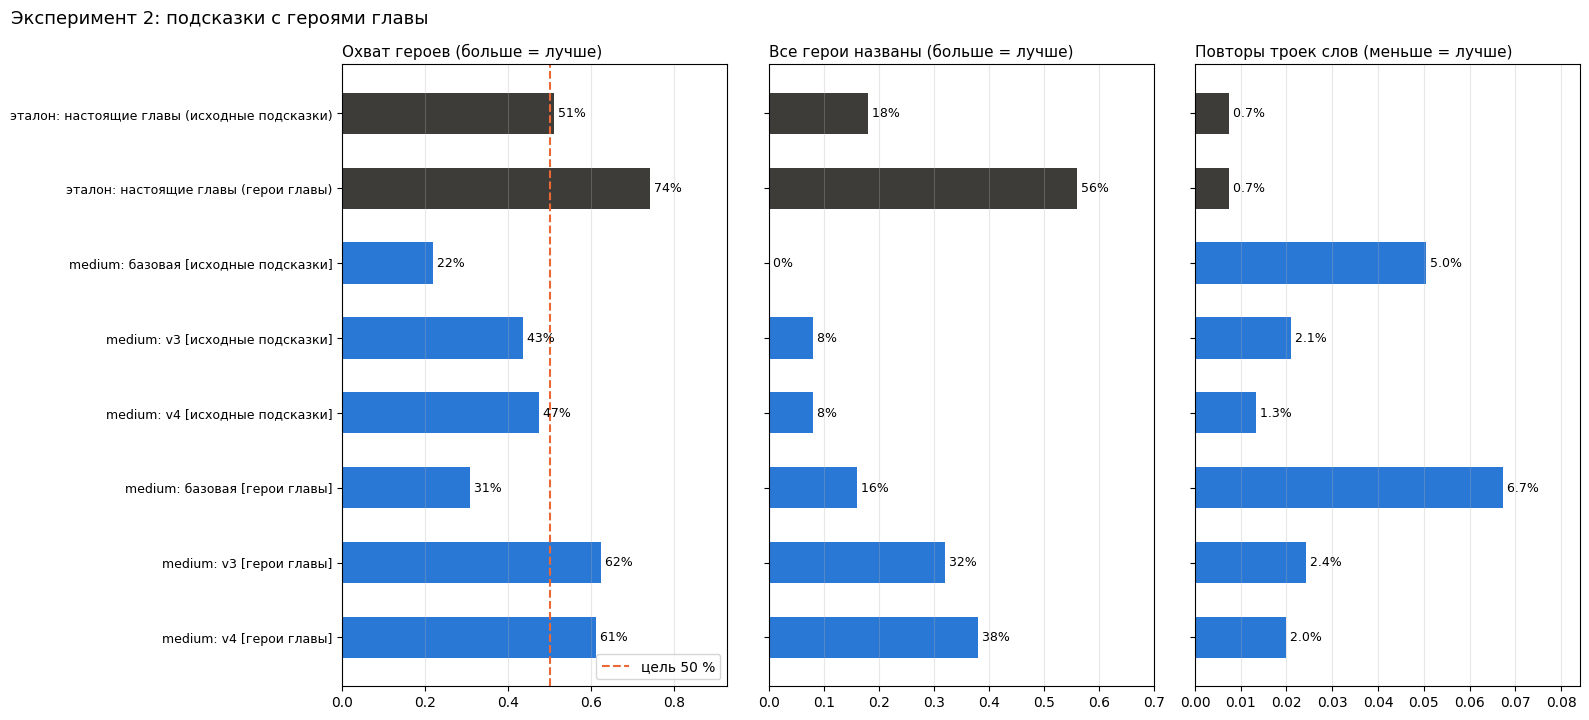

In [33]:
GEN = dict(repetition_penalty=1.0, no_repeat_ngram_size=4)
V4_ADAPTER = os.path.join(V4_DIR, "adapter")

res2 = {REF_NAME + " (исходные подсказки)": results[REF_NAME]}
ref_f = [tok.decode(tok.encode(ex["completion"].replace("</s>", ""), add_special_tokens=False)[:MAX_NEW_TOKENS])
         for ex in eval_f]
res2[REF_NAME + " (герои главы)"] = score(prompts_f, ref_f)

for tag, pr in [("исходные подсказки", prompts), ("герои главы", prompts_f)]:
    runs = {
        f"medium: базовая [{tag}]": (None, GEN),
        f"medium: v3 [{tag}]": (ADAPTER_V3, GEN),
        f"medium: v4 [{tag}]": (V4_ADAPTER, GEN),
    }
    for name, (adapter, kw) in runs.items():
        r, _ = run_variants(MEDIUM, adapter, {name: kw}, pr, OUT_DIR, tok)
        res2.update(r)

print(results_table(res2))
plot_results(res2, "Эксперимент 2: подсказки с героями главы", os.path.join(OUT_DIR, "exp2_heroes_in_chapter.png"))
with open(os.path.join(OUT_DIR, "exp2_metrics.md"), "w", encoding="utf-8") as f:
    f.write(results_table(res2))

### Вывод по эксперименту 2 (50 подсказок)

Гипотеза 2 подтверждена **лишь частично**.

1. **v4 почти ничего не добавила к v3.** На исходных подсказках охват 47 % против 43 %, на подсказках с героями главы 61 % против 62 %, «все герои названы» 38 % против 32 %, перплексия на исправленных val и test одинакова (16,7 и 14,1). Разница в 1–6 процентных пунктов на 50 подсказках меньше случайного разброса (около ±8 п.п.), поэтому утверждать, что v4 лучше v3, нельзя. Это проверяется на большей выборке в эксперименте 2б.
2. **Главный результат другой: охват зависит от того, каких героев перечислили в подсказке.** Если в подсказке только герои, которые есть в главе, то даже v3 называет 62 % героев (против 43 % при героях всей сказки), а настоящие главы дают 74 % (против 51 %). Просить назвать героя, которого глава по сюжету не упоминает, бессмысленно и для автора сказки. В продукте ребёнок выбирает героев именно этой главы, поэтому реальный сценарий — вторая постановка.
3. **Дообучение даёт большой прирост при любой постановке.** Базовая модель: 22 % (исходные) и 31 % (герои главы), дообученные: 43–47 % и 61–62 %. Мусор в тексте падает с 30–34 % до 0 %.
4. **Цель.** Формально «охват ≥ 50 % на исходных подсказках» не достигнут (47 %, у настоящих глав 51 %). В реалистичной постановке с героями главы цель достигнута (61 %), но остаётся отставание от настоящих глав на 13 п.п. (74 %) и по показателю «все герои названы» (38 % против 56 %).

## 9. Эксперимент 2б: проверка на большой выборке и доверительные интервалы

На 50 подсказках разброс метрики около ±8 п.п., и различия v3 и v4 ему сопоставимы. Повторяем сравнение на большей выборке (до 250 подсказок из теста, это почти весь тест) и считаем 95 % доверительные интервалы бутстрепом: подсказки перевыбираются с возвращением 2000 раз. Для разницы v4 − v3 интервал парный: на одних и тех же подсказках. Обучения нет, около 20 минут на T4.

In [34]:
BIG_N = 250
eval_big = pick_eval_set(test_raw, tok, n=BIG_N)
eval_big_f = [keep_chapter_heroes(ex) or ex for ex in eval_big]
prompts_big = [ex["prompt"] for ex in eval_big]
prompts_big_f = [ex["prompt"] for ex in eval_big_f]
print("Подсказок в большой выборке:", len(prompts_big))


def per_prompt_coverage(prompts_, texts):
    # Охват героев по каждой подсказке (None, если героев в подсказке нет)
    return [hero_coverage(p, t) for p, t in zip(prompts_, texts)]


def bootstrap_ci(values, n_boot=2000, seed=SEED):
    # 95 % доверительный интервал среднего (бутстреп по подсказкам)
    rng = random.Random(seed)
    n = len(values)
    means = sorted(sum(values[rng.randrange(n)] for _ in range(n)) / n for _ in range(n_boot))
    return means[int(0.025 * n_boot)], means[int(0.975 * n_boot)]


def paired_diff_ci(a, b, n_boot=2000, seed=SEED):
    # Среднее и 95 % интервал разницы a - b на одних и тех же подсказках
    diffs = [x - y for x, y in zip(a, b)]
    return (sum(diffs) / len(diffs),) + bootstrap_ci(diffs, n_boot, seed)


big_cov, big_res = {}, {}
for tag, pr in [("исходные подсказки", prompts_big), ("герои главы", prompts_big_f)]:
    for label, adapter in [("базовая", None), ("v3", ADAPTER_V3), ("v4", V4_ADAPTER)]:
        name = f"большая выборка: {label} [{tag}]"
        r, g = run_variants(MEDIUM, adapter, {name: GEN}, pr, OUT_DIR, tok)
        big_res.update(r)
        pairs = [(i, c) for i, c in enumerate(per_prompt_coverage(pr, g[name])) if c is not None]
        big_cov[(label, tag)] = dict(pairs)

lines = ["| Постановка | Модель | Охват героев (95 % ИД) | Все герои названы |", "|---|---|---|---|"]
for tag in ["исходные подсказки", "герои главы"]:
    for label in ["базовая", "v3", "v4"]:
        cov = big_cov[(label, tag)]
        vals = [cov[i] for i in sorted(cov)]
        lo, hi = bootstrap_ci(vals)
        name = f"большая выборка: {label} [{tag}]"
        lines.append(f"| {tag} | {label} | {sum(vals) / len(vals):.0%} ({lo:.0%}–{hi:.0%}) | "
                     f"{big_res[name]['all_heroes']:.0%} |")
table_big = "\n".join(lines)
print(table_big)

print()
for tag in ["исходные подсказки", "герои главы"]:
    a, b = big_cov[("v4", tag)], big_cov[("v3", tag)]
    common = sorted(set(a) & set(b))
    d, lo, hi = paired_diff_ci([a[i] for i in common], [b[i] for i in common])
    verdict = "различие значимо" if lo > 0 or hi < 0 else "различие в пределах шума"
    print(f"{tag}: v4 − v3 = {d:+.1%} (95 % ИД {lo:+.1%} … {hi:+.1%}), {verdict}")

with open(os.path.join(OUT_DIR, "exp2b_metrics.md"), "w", encoding="utf-8") as f:
    f.write(table_big)

Подсказок в большой выборке: 250
Loading weights:   0%|          | 0/293 [00:00<?, ?it/s]
[transformers] GPT2LMHeadModel LOAD REPORT from: ai-forever/rugpt3medium_based_on_gpt2
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...23}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
большая выборка: базовая [исходные подсказки]: готово за 3.3 мин
    {'hero_coverage': 0.26, 'all_heroes': 0.084, 'junk': 0.404, 'repeat3': 0.096, 'words': 189.504, 'n': 250}
Loading weights:   0%|          | 0/293 [00:00<?, ?it/s]
[transformers] GPT2LMHeadModel LOAD REPORT from: ai-forever/rugpt3medium_based_on_gpt2
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...23}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be 

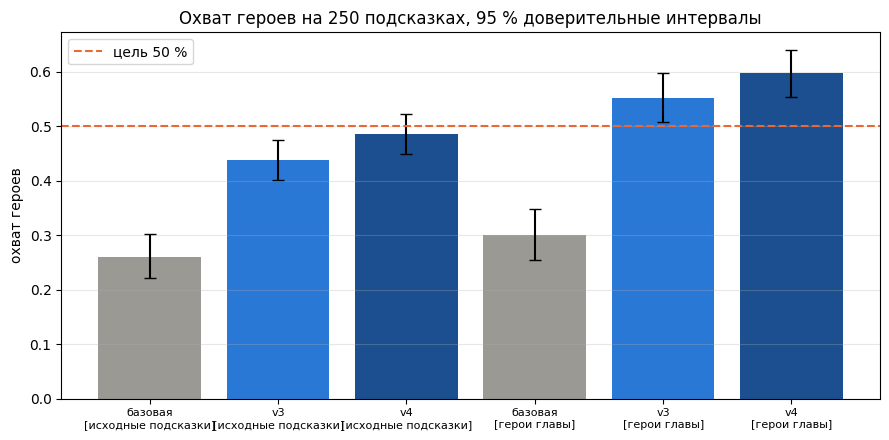

In [35]:
fig, ax = plt.subplots(figsize=(9, 4.5))
labels, means, errs = [], [], []
for tag in ["исходные подсказки", "герои главы"]:
    for label in ["базовая", "v3", "v4"]:
        cov = big_cov[(label, tag)]
        vals = [cov[i] for i in sorted(cov)]
        lo, hi = bootstrap_ci(vals)
        m = sum(vals) / len(vals)
        labels.append(f"{label}\n[{tag}]")
        means.append(m)
        errs.append((m - lo, hi - m))
colors = ["#9a9993", "#2a78d6", "#1b4f8f"] * 2
ax.bar(range(len(means)), means, yerr=list(zip(*errs)), color=colors, capsize=4)
ax.axhline(0.5, color="#eb6834", linestyle="--", label="цель 50 %")
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("охват героев")
ax.set_title(f"Охват героев на {len(prompts_big)} подсказках, 95 % доверительные интервалы")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "exp2b_big_sample.png"), dpi=150)
plt.show()

### Вывод по эксперименту 2б (250 подсказок, 95 % доверительные интервалы)

**v4 лучше v3 на несколько процентных пунктов, и разница статистически значима.** Охват героев v4 − v3 на исходных подсказках +4,7 п.п. (95 % ИД +1,0 … +8,4), на подсказках с героями главы +4,5 п.п. (95 % ИД +0,1 … +8,9). На 50 подсказках эту разницу нельзя было отличить от шума, на 250 она видна, хотя во второй постановке нижняя граница интервала почти упирается в ноль. Показатель «все герои названы» тоже выше у v4: 12 % против 9 % и 35 % против 30 %.

**Сравнение с базовой моделью (охват героев, 95 % ИД):**

| Постановка | базовая | v3 | v4 |
|---|---|---|---|
| исходные подсказки | 26 % (22–30) | 44 % (40–47) | 48 % (45–52) |
| герои главы | 30 % (25–35) | 55 % (51–60) | 60 % (55–64) |

**Цель «охват героев ≥ 50 %».**
- На исходных подсказках v4 даёт 48 %, интервал 45–52 % включает 50 %, но точечная оценка ниже. Цель достигнута почти, но не с уверенностью.
- На подсказках с героями главы, то есть в реальном сценарии продукта, v4 даёт 60 % (55–64 %), нижняя граница интервала выше 50 %. Цель достигнута.

**Итог по гипотезе 2.** Исправление подсказок (убрать героев, которых нет в главе) даёт небольшой, но значимый выигрыш около 5 п.п. Основной вклад вносят дообучение (охват с 26–30 % до 44–60 %) и способ генерации из эксперимента 1 (с 27 % до 44 % без переобучения). Финальной моделью выбрана v4: она показала лучшие результаты в обеих постановках и обучена на тех же подсказках, что будут в боте.

Замечание о воспроизводимости: повторный прогон тех же моделей с тем же зерном дал на v4 охват 48,5 % вместо 49,7 %, то есть случайность генерации на GPU даёт разброс около одного процентного пункта; разницы меньше 1–2 п.п. интерпретировать нельзя.


In [36]:
import shutil
from IPython.display import FileLink

archive = shutil.make_archive("/kaggle/working/v4_adapter", "zip", V4_DIR)
print("Архив:", archive, f"{os.path.getsize(archive) / 1e6:.0f} МБ")
FileLink("v4_adapter.zip")

Архив: /kaggle/working/v4_adapter.zip 23 МБ


/kaggle/working/v4_adapter.zip

## 10. Эксперимент 3: ранг LoRA 64 (гипотеза 3)

Обучение и оценка вынесены в отдельный ноутбук `03_experiment_rank64.ipynb` (с выводами): в этом ноутбуке уже выполнены все эксперименты до v4, а ещё одно обучение на 70 минут здесь не помещается в одну сессию. Данные, настройки обучения, оценочные подсказки и метрики те же. Меняется только ранг: r = 64 и lora_alpha = 128 вместо r = 16 и 32 (обучаемых параметров 25,2 млн вместо 6,29 млн).

| | v4 (r = 16) | v5 (r = 64) |
|---|---|---|
| Перплексия val / test (исправленные подсказки; базовая 18,7 / 16,2) | 16,7 / 14,1 | 16,7 / 14,0 |
| Охват героев, исходные подсказки (250) | 50 % (46–53) | 49 % (45–52) |
| Охват героев, герои главы (250) | 60 % (55–64) | 61 % (56–65) |
| Все герои названы, исходные / герои главы | 13 % / 35 % | 12 % / 34 % |

### Вывод по эксперименту 3

**Гипотеза 3 не подтвердилась.** Разница v5 − v4 по охвату героев равна −0,9 п.п. (95 % ИД −4,2 … +2,5) на исходных подсказках и +0,9 п.п. (−3,3 … +5,0) на подсказках с героями главы: оба интервала содержат ноль. Перплексия не изменилась. Ошибка на val у v5 перестаёт падать после шага 308, а ошибка на train продолжает снижаться: большая ёмкость идёт на подгонку под обучающие данные. Значит, следование подсказке ограничивает не ёмкость адаптера, а данные: герои часто названы только в соседних главах, а корпус мал (около 2700 примеров). Финальной остаётся модель v4: точность та же, обучаемых параметров в четыре раза меньше. (Охват v4 на тех же подсказках в этом прогоне 50 % / 60 %, в разделе 9 48 % / 60 %: разброс генерации на GPU около 1–2 п.п.)


## 11. Итоги: все модели, параметры, точность и выбор лучшей

### Сводная таблица

Параметры LoRA: у small (12 слоёв, ранг 16) обучается 2,36 млн параметров, у medium (24 слоя, ранг 16) — 6,29 млн из 362 млн (1,74 %). Базовые модели при обучении заморожены.

| Модель | Данные и окно | Эпохи | Перплексия val / test | Охват героев, 250 подсказок: исходные / герои главы |
|---|---|---|---|---|
| small, базовая (≈125 млн) | — | — | 26,1 / 23,1 | не измерялось |
| small + LoRA v1 | исходные подсказки, окно 1024 | 3 | 23,3 / 20,4 | не измерялось |
| small + LoRA v2 | исходные подсказки, окно 1024 | 8 (лучший шаг ≈700) | 22,8 / 19,3 | не измерялось |
| medium, базовая (≈356 млн) | — | — | 18,9 / 16,6 (на исправленных подсказках 18,7 / 16,2) | 26 % / 30 % |
| medium + LoRA v3 | исходные подсказки, окно 2048 | 6 (лучший шаг 528) | 16,9 / 14,5 (на исправленных 16,7 / 14,1) | 44 % / 55 % |
| **medium + LoRA v4** | подсказки с героями главы, окно 2048 | 4 (лучший шаг 660) | 16,7 / 14,1 (на исправленных) | **48 % / 60 %** |
| medium + LoRA v5, ранг 64 (25,2 млн обучаемых параметров) | как v4 | 4 (лучший шаг 308) | 16,7 / 14,0 (на исправленных) | 49 % / 61 % (прогон в ноутбуке 3, см. раздел 10) |

Примечания к таблице:
- Перплексия у разных размеров модели и разной длины окна сравнима лишь приблизительно. Перплексия v3 и v4 на исправленных val и test одинакова, различие между ними проявилось только в метрике следования подсказке.
- Охват героев у small не пересчитывался с выбранной настройкой генерации (запрет повторов 4-грамм). Цифры этапа 4 получены со штрафом 1.1, который занижает охват, поэтому в таблицу они не включены.
- В этапе 4 охват измерялся на 50 подсказках, здесь на 250: на 50 подсказках разброс около ±8 п.п., на 250 около ±4 п.п.

### Выбор лучшей модели

**Лучшая модель: medium + LoRA v4.** По перплексии medium заметно лучше small (test 14,1 против 19,3 у лучшей small) при том, что обучаемых параметров всего в 2,7 раза больше (6,29 млн против 2,36 млн), а базовая модель в три раза крупнее. Среди medium-вариантов (v3, v4, v5 с рангом 64) v4 не уступает v3 по перплексии и значимо лучше по охвату героев (+4,7 п.п. на исходных и +4,5 п.п. на подсказках с героями главы). Обучение v4 короче (4 эпохи против 6). Ранг 64 (v5) точности не добавил, при этом параметров в четыре раза больше, поэтому выбран ранг 16. Для продукта, где ребёнок выбирает героев главы, v4 обучена на тех же подсказках, что будут в боте.

### Удалось ли добиться желаемой точности

**Цель 1: охват героев ≥ 50 % на 50 тестовых подсказках из этапа 4** (у настоящих глав 51 %). На 250 подсказках v4 даёт 48 % (95 % ИД 45–52 %): цель почти достигнута, но с уверенностью утверждать это нельзя. В реальном сценарии, когда в подсказке указаны герои главы, v4 даёт 60 % (55–64 %), цель достигнута с запасом.

**Цель 2: перплексия на test ниже, чем у базовой модели.** Достигнута: 14,1 против 16,2 на исправленных подсказках (14,5 против 16,6 на исходных у v3).

### Почему полностью цель не достигнута и что показали гипотезы

1. **Штраф за повторы при генерации (гипотеза 1, подтверждена).** Главная причина «неуспеха» в этапе 4: `repetition_penalty = 1.1` штрафует токены подсказки, а имена героев стоят в подсказке. Без штрафа и с запретом повторов 4-грамм охват вырос с 27 % до 43–45 % у той же модели.
2. **Подсказка расходится с текстом (гипотеза 2, подтверждена частично).** В обучающих данных только 66 % героев из подсказки встречаются в главе, и даже в настоящих главах охват героев всей сказки равен 51 %. После исправления подсказок охват вырос на ~5 п.п. и разница значима, но невелика.
3. **Ёмкость адаптера (гипотеза 3, не подтверждена).** Ранг LoRA 64 (в четыре раза больше обучаемых параметров) не дал выигрыша: охват героев 49 % / 61 % против 50 % / 60 % у v4 (разница в пределах шума), перплексия на test 14,0 против 14,1. Значит, ёмкость адаптера не ограничивает следование подсказке (раздел 10).

Остающееся отставание (60 % у v4 против 74 % у настоящих глав при подсказках с героями главы; «все герои названы» 35 % против 56 %) связано, по-видимому, с малым объёмом данных (около 2700 примеров) и с тем, что модель учится на коротких фрагментах длинных сказок: имя героя часто встречается только в предыдущих главах.

### Другие способы решения проблемы

- **Выбор из нескольких вариантов (rejection sampling).** Генерировать 3–5 глав и выбирать ту, где названы все герои из запроса. Это не требует переобучения и использует уже написанную проверку `check_heroes`.
- **Принудительное включение героев при генерации** (ограничения на декодирование, подсказка начинается с имени героя) или подстановка имени ребёнка в текст.
- **Больше и чище данных:** расширить корпус, заново разметить героев по главам, добавить синтетические примеры.
- **Более крупная модель** (например, ruGPT3 large) с QLoRA или API большой модели как запасной вариант.
- **Другие гиперпараметры** (скорость обучения, число эпох, целевые модули LoRA): ранг 64 пользы не принёс (раздел 10), поэтому ожидать многого от подбора гиперпараметров не стоит.
- **Оценка людьми** по шкале 1–5 (связность, сюжет, понятность ребёнку, мораль): она заявлена в этапе 1 и пока не проведена, автоматические метрики её не заменяют.
